# Three Simple Cheat Detectors (NumPy only)

Three models, each adding one idea to the one before it:

| Model | Formula | New idea |
|---|---|---|
| 1. Linear regression | score = X·w + b | fit a straight line with MSE |
| 2. Logistic regression | p = sigmoid(X·w + b) | squash the score into a probability, use cross-entropy |
| 3. Neural network | p = sigmoid(ReLU(X·W1 + b1)·w2 + b2) | a hidden layer lets the model learn curved patterns |

All three are trained with the same loop: **Predict → Loss → Gradient → Update**.

In [25]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(0)
df = pd.read_csv("data/kill_features.csv", dtype={"steamid": str})
print("kills:", len(df), " players:", df["steamid"].nunique(),
      " cheaters:", df.loc[df["is_cheater"] == 1, "steamid"].nunique(),
      " demos:", df["demo"].nunique() if "demo" in df.columns else "?")

kills: 20295  players: 1776  cheaters: 466  demos: 200


## Step 1: Features (X) and label (y)

In [26]:
FEATURES = [
    "head_ang_err", "head_miss_units", "chest_ang_err", "spatial_dist_to_target",
    "on_head_at_kill", "headshot",
    "ms_on_target", "approach_peak_ang_vel", "acquired_from_deg",
    "mean_ang_vel", "max_ang_vel", "max_abs_jerk", "frac_window_on_head",
    "head_err_last_half_s", "ang_vel_std_last_half_s", "head_err_early",
]
FEATURES = [f for f in FEATURES if f in df.columns]
# Speeds and distances can be huge (a 5000 deg/s flick), so take the log of them
LOG = {"head_ang_err", "head_miss_units", "chest_ang_err", "spatial_dist_to_target",
       "ms_on_target", "approach_peak_ang_vel", "acquired_from_deg", "mean_ang_vel",
       "max_ang_vel", "max_abs_jerk", "head_err_last_half_s", "ang_vel_std_last_half_s",
       "head_err_early"}

## Step 2: Split by player (60% train / 20% validation / 20% test)
A player's kills all go into the **same** split. Otherwise the model could learn to recognise *that player* instead of *cheating*.

In [27]:
def split_players(part, val_frac=0.2, test_frac=0.2, seed=0):
    """Returns {steamid: 'train' / 'val' / 'test'}. Cheaters and clean players are split separately."""
    players = part.groupby("steamid")["is_cheater"].max()
    rng = np.random.default_rng(seed)
    split_of = {}
    for label in [0, 1]:
        ids = players[players == label].index.to_numpy()
        rng.shuffle(ids)
        n_test = round(test_frac * len(ids)) if test_frac else 0
        n_val = round(val_frac * len(ids))
        if len(ids) >= 3:                                 # at least 1 in each split when possible
            n_test = max(n_test, 1) if test_frac else 0
            n_val = max(n_val, 1)
        for i, sid in enumerate(ids):
            split_of[sid] = "test" if i < n_test else "val" if i < n_test + n_val else "train"
    return split_of


df["split"] = df["steamid"].map(split_players(df))
print(df.groupby("split").agg(kills=("is_cheater", "size"), cheater_kills=("is_cheater", "sum")))

       kills  cheater_kills
split                      
test    3765           1219
train  12389           3820
val     4141           1427


## Step 3: Prepare the numbers
Log transform, fill blanks with the median value, then normalize to mean  to 0 and the std 1.
Every statistic comes from the training set so no test information leaks in.

In [28]:
def to_matrix(part, features):
    X = part[features].astype(float).to_numpy()
    for j, f in enumerate(features):
        if f in LOG:
            X[:, j] = np.log1p(np.clip(X[:, j], 0, None))
    return X


def fit_prep(train_part, features):
    M = to_matrix(train_part, features)
    with np.errstate(all="ignore"):
        median = np.nanmedian(M, axis=0)
    median = np.where(np.isnan(median), 0, median)
    M = np.where(np.isnan(M), median, M)
    std = M.std(axis=0)
    std[std == 0] = 1
    return {"features": list(features), "median": median, "mean": M.mean(axis=0), "std": std}


def apply_prep(part, prep):
    M = to_matrix(part, prep["features"])
    return (np.where(np.isnan(M), prep["median"], M) - prep["mean"]) / prep["std"]


prep = fit_prep(df[df["split"] == "train"], FEATURES)
X = {s: apply_prep(df[df["split"] == s], prep) for s in ["train", "val", "test"]}
y = {s: df.loc[df["split"] == s, "is_cheater"].to_numpy().astype(float) for s in ["train", "val", "test"]}
print("X_train shape:", X["train"].shape)

X_train shape: (12389, 16)


Cheater kills are much rarer than non cheater kills, so each one gets a bigger weight in the loss. Without this a model can score well just by always saying no one is cheating.

In [ ]:
def kill_weights(y):
    n_pos = y.sum()
    n_neg = len(y) - n_pos
    sw = np.where(y == 1, len(y) / (2 * n_pos), len(y) / (2 * n_neg))
    return sw / sw.mean()          # average weight of 1

## Model 1: Linear regression
The output is a **score**, not a true probability: it can go below 0 or above 1.

In [30]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def train_linear(X, y, sw, lr=0.01, epochs=2000):
    n, k = X.shape
    w, b = np.zeros(k), 0.0
    losses = []
    for epoch in range(epochs):
        y_hat = X @ w + b                              # 1. PREDICT
        error = y_hat - y
        loss = np.mean(sw * error ** 2)                # 2. LOSS (MSE)
        dw = 2 * X.T @ (sw * error) / n                # 3. GRADIENT
        db = 2 * np.mean(sw * error)
        w -= lr * dw                                   # 4. UPDATE
        b -= lr * db
        losses.append(loss)
    return {"type": "linear", "w": w, "b": b, "losses": losses}

## Model 2: Logistic regression
Same line, then sigmoid turns it into a probability between 0 and 1. The loss is cross-entropy, and the gradient is prediction minus truth.

In [31]:
def train_logistic(X, y, sw, lr=0.1, epochs=2000):
    n, k = X.shape
    w, b = np.zeros(k), 0.0
    losses = []
    for epoch in range(epochs):
        p = sigmoid(X @ w + b)                                                  # 1. PREDICT
        loss = -np.mean(sw * (y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9)))  # 2. LOSS
        dw = X.T @ (sw * (p - y)) / n                                           # 3. GRADIENT
        db = np.mean(sw * (p - y))
        w -= lr * dw                                                            # 4. UPDATE
        b -= lr * db
        losses.append(loss)
    return {"type": "logistic", "w": w, "b": b, "losses": losses}

## Model 3: Neural network (one hidden layer)
The inputs go into **8 hidden neurons** with **ReLU**, then one output neuron with **sigmoid**.
- **Forward pass:** compute the prediction layer by layer.
- **Backpropagation:** send the error (*prediction minus truth*) back through the layers to get each weight's gradient.

In [32]:
def relu(z):
    return np.maximum(0, z)


def train_network(X, y, sw, hidden=8, lr=0.1, epochs=2000, seed=0):
    n, k = X.shape
    r = np.random.default_rng(seed)
    W1 = r.normal(0, np.sqrt(2 / k), size=(k, hidden))   # small random starting weights
    b1 = np.zeros(hidden)
    w2 = r.normal(0, np.sqrt(2 / hidden), size=hidden)
    b2 = 0.0
    losses = []
    for epoch in range(epochs):
        # 1. PREDICT (forward pass)
        Z1 = X @ W1 + b1
        A1 = relu(Z1)
        p = sigmoid(A1 @ w2 + b2)
        # 2. LOSS
        loss = -np.mean(sw * (y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9)))
        # 3. GRADIENT (backpropagation)
        d_out = sw * (p - y) / n                 # prediction minus truth
        dw2 = A1.T @ d_out
        db2 = d_out.sum()
        d_hidden = np.outer(d_out, w2) * (Z1 > 0)   # error sent back through ReLU
        dW1 = X.T @ d_hidden
        db1 = d_hidden.sum(axis=0)
        # 4. UPDATE
        W1 -= lr * dW1; b1 -= lr * db1
        w2 -= lr * dw2; b2 -= lr * db2
        losses.append(loss)
    return {"type": "network", "W1": W1, "b1": b1, "w2": w2, "b2": b2, "losses": losses}

One `predict` function for all three using the model's weights

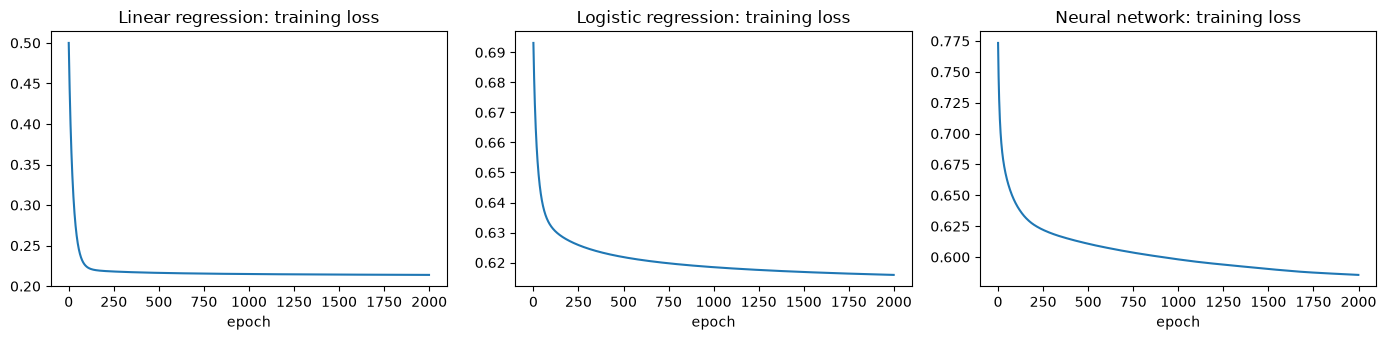

In [33]:
def predict(model, X):
    if model["type"] == "linear":
        return X @ model["w"] + model["b"]
    if model["type"] == "logistic":
        return sigmoid(X @ model["w"] + model["b"])
    return sigmoid(relu(X @ model["W1"] + model["b1"]) @ model["w2"] + model["b2"])


TRAINERS = {"Linear regression": train_linear,
            "Logistic regression": train_logistic,
            "Neural network": train_network}

sw = kill_weights(y["train"])
models = {}
for name, trainer in TRAINERS.items():
    t0 = time.perf_counter()
    models[name] = trainer(X["train"], y["train"], sw)
    models[name]["seconds"] = time.perf_counter() - t0

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, m) in zip(axes, models.items()):
    ax.plot(m["losses"]); ax.set_title(f"{name}: training loss"); ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Step 4: Choose each model's cut-off on the validation set
Each model outputs a score. Above the **threshold** = "cheater". The threshold that gives the best F1 on the **validation** players is kept, then used unchanged on the test players.

In [34]:
def scores(y_true, pred):
    tp = np.sum((pred == 1) & (y_true == 1)); fp = np.sum((pred == 1) & (y_true == 0))
    fn = np.sum((pred == 0) & (y_true == 1)); tn = np.sum((pred == 0) & (y_true == 0))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"accuracy": (tp + tn) / len(y_true), "precision": precision, "recall": recall,
            "f1": f1, "false_flag_rate": fp / (fp + tn) if fp + tn else 0.0}


def pick_threshold(model, X_val, y_val):
    val_scores = predict(model, X_val)
    if len(y_val) == 0 or y_val.sum() == 0:
        return float(np.median(val_scores)) if len(y_val) else 0.5
    candidates = np.quantile(val_scores, np.linspace(0.05, 0.95, 37))
    f1s = [scores(y_val, (val_scores >= t).astype(int))["f1"] for t in candidates]
    return float(candidates[int(np.argmax(f1s))])


for name, m in models.items():
    m["threshold"] = pick_threshold(m, X["val"], y["val"])
    print(f"{name:20s} threshold = {m['threshold']:.3f}")

Linear regression    threshold = 0.486
Logistic regression  threshold = 0.477
Neural network       threshold = 0.529


## Step 5: Compare on the test players

In [ ]:
rows = []
for name, m in models.items():
    t0 = time.perf_counter()
    test_scores = predict(m, X["test"])
    us_per_kill = (time.perf_counter() - t0) / len(X["test"]) * 1e6
    pred = (test_scores >= m["threshold"]).astype(int)
    rows.append({"model": name, **scores(y["test"], pred),
                 "train_seconds": m["seconds"], "µs_per_kill": us_per_kill})
always_clean = scores(y["test"], np.zeros(len(y["test"]), dtype=int))
rows.append({"model": "Baseline", **always_clean})
results = pd.DataFrame(rows).set_index("model")
results.round(3)

,accuracy,precision,recall,f1,false_flag_rate,train_seconds,µs_per_kill
model,,,,,,,
Linear regression,0.652,0.475,0.740,0.579,0.391,0.877,0.015
Logistic regression,0.651,0.475,0.741,0.579,0.392,0.565,0.016
Neural network,0.704,0.536,0.633,0.581,0.262,3.142,0.037
Baseline: always clean,0.676,0.000,0.000,0.000,0.000,NaN,NaN


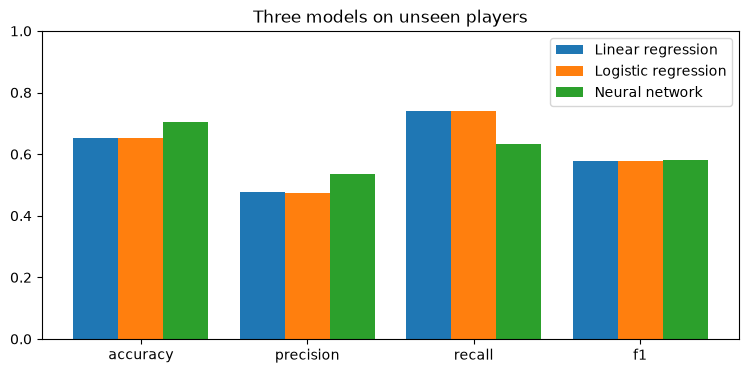

In [36]:
metrics = ["accuracy", "precision", "recall", "f1"]
x = np.arange(len(metrics))
plt.figure(figsize=(9, 4))
for i, name in enumerate(models):
    plt.bar(x + (i - 1) * 0.27, results.loc[name, metrics], 0.27, label=name)
plt.xticks(x, metrics); plt.ylim(0, 1); plt.legend()
plt.title("Three models on unseen players"); plt.show()

## Step 6: What did the simple models learn?
Features are normalized, so the weights can be compared: **positive = points toward cheating**. The neural network has no single weight per feature, which makes it harder to explain. That's a trade-off worth mentioning.

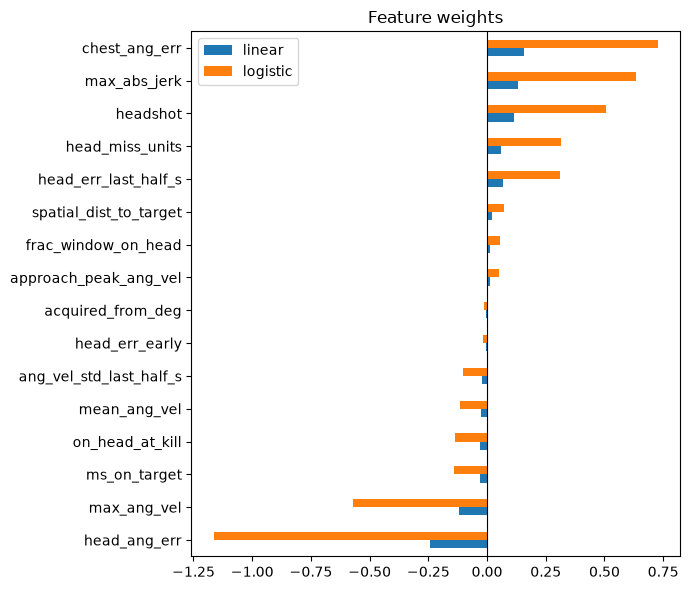

In [37]:
weights = pd.DataFrame({"linear": models["Linear regression"]["w"],
                        "logistic": models["Logistic regression"]["w"]}, index=FEATURES)
weights.sort_values("logistic").plot.barh(figsize=(7, 6))
plt.axvline(0, color="k", lw=0.8); plt.title("Feature weights"); plt.tight_layout(); plt.show()

## Step 7: Save the models (their "memory")
Everything a model learned is in its **weights**. Those are ordinary Python variables, so they vanish when the notebook closes unless they're saved to a file.

Each file also stores the **preparation numbers** from Step 3 (median, mean, std), the **feature list** and the **threshold**. Without them, new data would be prepared differently from the training data and the weights would no longer fit.

In [38]:
os.makedirs("models", exist_ok=True)
WEIGHT_KEYS = {"linear": ["w", "b"], "logistic": ["w", "b"], "network": ["W1", "b1", "w2", "b2"]}


def save_model(model, prep, path):
    np.savez(path,
             type=model["type"], threshold=model["threshold"],
             features=np.array(prep["features"]),
             median=prep["median"], mean=prep["mean"], std=prep["std"],
             **{k: model[k] for k in WEIGHT_KEYS[model["type"]]})


def load_model(path):
    f = np.load(path)
    model_type = str(f["type"])
    model = {"type": model_type, "threshold": float(f["threshold"]),
             **{k: f[k] for k in WEIGHT_KEYS[model_type]}}
    prep = {"features": [str(x) for x in f["features"]],
            "median": f["median"], "mean": f["mean"], "std": f["std"]}
    return model, prep


MODEL_FILES = {"Linear regression": "models/linear.npz",
               "Logistic regression": "models/logistic.npz",
               "Neural network": "models/network.npz"}
for name, m in models.items():
    save_model(m, prep, MODEL_FILES[name])
    print("saved", MODEL_FILES[name], f"({os.path.getsize(MODEL_FILES[name])} bytes)")

saved models/linear.npz (3974 bytes)
saved models/logistic.npz (3982 bytes)
saved models/network.npz (5478 bytes)


## Step 8: Load the saved models and score kills
This cell works on its own in a **new** notebook (with the functions above): it needs only the `.npz` files.

First a check that a loaded model gives exactly the same answers as the one that was saved, then the same function scores any table of kills built by `build_dataset.py`.

In [39]:
def score_kills(kills, model_path):
    """Probability (or score) and verdict for every kill, using a saved model."""
    model, saved_prep = load_model(model_path)
    s = predict(model, apply_prep(kills, saved_prep))
    out = kills[["player_alias"]].copy() if "player_alias" in kills.columns else pd.DataFrame(index=kills.index)
    out["score"] = s
    out["flagged"] = s >= model["threshold"]
    return out


test_part = df[df["split"] == "test"]
for name, path in MODEL_FILES.items():
    same = np.allclose(score_kills(test_part, path)["score"], predict(models[name], X["test"]))
    print(f"{name:20s} reloaded model matches original: {same}")

# Example: score the kills from one demo with the saved neural network.
# For a NEW demo: add it to DEMOS in build_dataset.py, run it, then pick its rows by the "demo" column.
# (Only a fair test if the model was not trained on that demo's players.)
example_demo = test_part["demo"].iloc[0] if "demo" in test_part.columns else None
new_kills = test_part[test_part["demo"] == example_demo] if example_demo else test_part
scored = score_kills(new_kills, MODEL_FILES["Neural network"])
print(f"\nDemo {example_demo}: {len(scored)} kills scored, {int(scored['flagged'].sum())} flagged")
scored.groupby("player_alias")["score"].agg(["size", "mean"]).rename(
    columns={"size": "kills", "mean": "average score"}).sort_values("average score", ascending=False).round(3)

Linear regression    reloaded model matches original: True
Logistic regression  reloaded model matches original: True
Neural network       reloaded model matches original: True

Demo with_cheater_present_0: 5 kills scored, 0 flagged


,kills,average score
player_alias,,
P0005,5,0.292


## Questions to discuss
- Did the neural network actually beat the simpler models, or is the difference small? With few players, one split can be lucky. Use the cross-validation in `cheat_detector.ipynb` before drawing conclusions.
- Linear regression scores can be below 0 or above 1. Why is that a problem if you want to say "the model is 80% sure"?
- Which model would you trust to **accuse** a player, and why?